In [1]:

import requests
# StatsBomb Open Data repository

BASE_URL = "https://raw.githubusercontent.com/statsbomb/open-data/master/data"

# Download competition information

url = f"{BASE_URL}/competitions.json"

response = requests.get(url)

# Check whether download is successful

if response.status_code == 200: #200 means request successful it is HTTPstatus code
    competitions = response.json()
    print("Dataset downloaded successfully!")
else:
    print("Download failed:", response.status_code)

Dataset downloaded successfully!


In [2]:

import pandas as pd
competitions_df = pd.DataFrame(competitions)

print("Dataset shape:", competitions_df.shape)

competitions_df.head()

Dataset shape: (80, 12)


,competition_id,season_id,country_name,competition_name,competition_gender,competition_youth,competition_international,season_name,match_updated,match_updated_360,match_available_360,match_available
0,9,281,Germany,1. Bundesliga,male,False,False,2023/2024,2024-09-28T20:46:38.893391,2025-11-15T23:17:41.827093,2025-11-15T23:17:41.827093,2024-09-28T20:46:38.893391
1,9,27,Germany,1. Bundesliga,male,False,False,2015/2016,2024-05-19T11:11:14.192381,None,None,2024-05-19T11:11:14.192381
2,1267,107,Africa,African Cup of Nations,male,False,True,2023,2026-05-12T21:18:08.827431,2026-05-02T02:07:18.902396,2026-05-02T02:07:18.902396,2026-05-12T21:18:08.827431
3,16,4,Europe,Champions League,male,False,False,2018/2019,2026-05-15T15:54:04.598614,2021-06-13T16:17:31.694,None,2026-05-15T15:54:04.598614
4,16,1,Europe,Champions League,male,False,False,2017/2018,2024-02-13T02:35:28.134882,2021-06-13T16:17:31.694,None,2024-02-13T02:35:28.134882


In [3]:
women_df = competitions_df[
    competitions_df["competition_gender"] == "female"
]

print("Number of women's competition-seasons:",
      len(women_df))

women_df.head(10)

Number of women's competition-seasons: 13


,competition_id,season_id,country_name,competition_name,competition_gender,competition_youth,competition_international,season_name,match_updated,match_updated_360,match_available_360,match_available
25,37,281,England,FA Women's Super League,female,False,False,2023/2024,2026-04-11T13:05:10.794831,None,None,2026-04-11T13:05:10.794831
26,37,90,England,FA Women's Super League,female,False,False,2020/2021,2026-04-12T16:33:48.145602,2021-06-13T16:17:31.694,None,2026-04-12T16:33:48.145602
27,37,42,England,FA Women's Super League,female,False,False,2019/2020,2026-04-12T16:07:56.102610,2021-06-13T16:17:31.694,None,2026-04-12T16:07:56.102610
28,37,4,England,FA Women's Super League,female,False,False,2018/2019,2026-03-28T18:13:53.368475,2021-06-13T16:17:31.694,None,2026-03-28T18:13:53.368475
38,135,281,Germany,Frauen Bundesliga,female,False,False,2023/2024,2026-04-11T13:05:50.947635,None,None,2026-04-11T13:05:50.947635
58,182,281,Spain,Liga F,female,False,False,2023/2024,2026-04-11T15:32:55.463202,None,None,2026-04-11T15:32:55.463202
66,49,107,United States of America,NWSL,female,False,False,2023,2026-04-08T09:41:46.347347,None,None,2026-04-08T09:41:46.347347
67,49,3,United States of America,NWSL,female,False,False,2018,2024-12-15T12:31:48.035735,2021-06-13T16:17:31.694,None,2024-12-15T12:31:48.035735
72,131,281,Italy,Serie A Women,female,False,False,2023/2024,2026-04-11T13:29:49.465639,None,None,2026-04-11T13:29:49.465639
76,53,315,Europe,UEFA Women's Euro,female,False,True,2025,2026-04-27T22:02:42.690507,2026-04-27T22:03:28.087062,2026-04-27T22:03:28.087062,2026-04-27T22:02:42.690507


In [4]:
women_df[
    [
        "competition_id",
        "season_id",
        "competition_name",
        "country_name",
        "season_name",
        "competition_gender"
    ]
]

,competition_id,season_id,competition_name,country_name,season_name,competition_gender
25,37,281,FA Women's Super League,England,2023/2024,female
26,37,90,FA Women's Super League,England,2020/2021,female
27,37,42,FA Women's Super League,England,2019/2020,female
28,37,4,FA Women's Super League,England,2018/2019,female
38,135,281,Frauen Bundesliga,Germany,2023/2024,female
58,182,281,Liga F,Spain,2023/2024,female
66,49,107,NWSL,United States of America,2023,female
67,49,3,NWSL,United States of America,2018,female
72,131,281,Serie A Women,Italy,2023/2024,female
76,53,315,UEFA Women's Euro,Europe,2025,female


In [5]:
selected_competition = women_df[
    (women_df["competition_id"] == 72) &
    (women_df["season_id"] == 107)
]

selected_competition

,competition_id,season_id,country_name,competition_name,competition_gender,competition_youth,competition_international,season_name,match_updated,match_updated_360,match_available_360,match_available
78,72,107,International,Women's World Cup,female,False,True,2023,2026-05-03T13:51:31.021141,2026-05-03T13:55:52.303219,2026-05-03T13:55:52.303219,2026-05-03T13:51:31.021141


In [6]:
competition_id = 72
season_id = 107

matches_url = (
    f"{BASE_URL}/matches/"
    f"{competition_id}/{season_id}.json"
)

response = requests.get(matches_url)

matches = response.json()

matches_df = pd.DataFrame(matches)

print("Total matches:", len(matches_df))

matches_df.head()

Total matches: 64


,match_id,match_date,kick_off,competition,season,home_team,away_team,home_score,away_score,match_status,match_status_360,last_updated,last_updated_360,metadata,match_week,competition_stage,stadium,referee
0,3893834,2023-08-03,10:00:00.000,"{'competition_id': 72, 'country_name': 'Intern...","{'season_id': 107, 'season_name': '2023'}","{'home_team_id': 2391, 'home_team_name': 'Moro...","{'away_team_id': 16802, 'away_team_name': 'Col...",1,0,available,available,2026-05-03T13:50:14.324089,2026-05-03T13:54:48.085709,"{'data_version': '1.1.0', 'shot_fidelity_versi...",3,"{'id': 10, 'name': 'Group Stage'}","{'id': 28891, 'name': 'HBF Park', 'country': {...","{'id': 1608, 'name': 'Maria Sole Ferrieri Capu..."
1,3893808,2023-07-27,01:00:00.000,"{'competition_id': 72, 'country_name': 'Intern...","{'season_id': 107, 'season_name': '2023'}","{'home_team_id': 1214, 'home_team_name': 'Unit...","{'away_team_id': 851, 'away_team_name': 'Nethe...",1,1,available,available,2026-05-03T13:49:22.028198,2026-05-03T13:54:26.772812,"{'data_version': '1.1.0', 'shot_fidelity_versi...",2,"{'id': 10, 'name': 'Group Stage'}","{'id': 98115, 'name': 'Wellington Regional Sta...","{'id': 2546, 'name': 'Yoshimi Yamashita', 'cou..."
2,3893818,2023-07-30,09:30:00.000,"{'competition_id': 72, 'country_name': 'Intern...","{'season_id': 107, 'season_name': '2023'}","{'home_team_id': 857, 'home_team_name': 'Germa...","{'away_team_id': 16802, 'away_team_name': 'Col...",1,2,available,available,2026-05-03T13:48:18.300577,2026-05-03T13:53:53.483974,"{'data_version': '1.1.0', 'shot_fidelity_versi...",2,"{'id': 10, 'name': 'Group Stage'}","{'id': 1001126, 'name': 'Allianz Stadium (Sydn...","{'id': 1626, 'name': 'Melissa Paola Borjas Pas..."
3,3893795,2023-07-22,12:00:00.000,"{'competition_id': 72, 'country_name': 'Intern...","{'season_id': 107, 'season_name': '2023'}","{'home_team_id': 853, 'home_team_name': 'Denma...","{'away_team_id': 1207, 'away_team_name': 'Chin...",1,0,available,available,2026-05-03T13:43:49.004030,2026-05-03T13:51:00.794205,"{'data_version': '1.1.0', 'shot_fidelity_versi...",1,"{'id': 10, 'name': 'Group Stage'}","{'id': 28891, 'name': 'HBF Park', 'country': {...","{'id': 1627, 'name': 'Marie-Soleil Beaudoin', ..."
4,3893825,2023-08-01,11:00:00.000,"{'competition_id': 72, 'country_name': 'Intern...","{'season_id': 107, 'season_name': '2023'}","{'home_team_id': 2355, 'home_team_name': 'Hait...","{'away_team_id': 853, 'away_team_name': 'Denma...",0,2,available,available,2026-05-03T13:43:30.247676,2026-05-03T13:50:35.097905,"{'data_version': '1.1.0', 'shot_fidelity_versi...",3,"{'id': 10, 'name': 'Group Stage'}","{'id': 28891, 'name': 'HBF Park', 'country': {...","{'id': 1006261, 'name': 'Hyeon-Jeong Oh', 'cou..."


In [7]:
print("Columns available in match dataset:")

print(matches_df.columns.tolist())

Columns available in match dataset:
['match_id', 'match_date', 'kick_off', 'competition', 'season', 'home_team', 'away_team', 'home_score', 'away_score', 'match_status', 'match_status_360', 'last_updated', 'last_updated_360', 'metadata', 'match_week', 'competition_stage', 'stadium', 'referee']


In [8]:
matches_df[
    [
        "match_id",
        "home_team",
        "away_team",
        "match_date"
    ]
].head(10)

,match_id,home_team,away_team,match_date
0,3893834,"{'home_team_id': 2391, 'home_team_name': 'Moro...","{'away_team_id': 16802, 'away_team_name': 'Col...",2023-08-03
1,3893808,"{'home_team_id': 1214, 'home_team_name': 'Unit...","{'away_team_id': 851, 'away_team_name': 'Nethe...",2023-07-27
2,3893818,"{'home_team_id': 857, 'home_team_name': 'Germa...","{'away_team_id': 16802, 'away_team_name': 'Col...",2023-07-30
3,3893795,"{'home_team_id': 853, 'home_team_name': 'Denma...","{'away_team_id': 1207, 'away_team_name': 'Chin...",2023-07-22
4,3893825,"{'home_team_id': 2355, 'home_team_name': 'Hait...","{'away_team_id': 853, 'away_team_name': 'Denma...",2023-08-01
5,3893798,"{'home_team_id': 861, 'home_team_name': 'Franc...","{'away_team_id': 1212, 'away_team_name': 'Jama...",2023-07-23
6,3893832,"{'home_team_id': 1212, 'home_team_name': 'Jama...","{'away_team_id': 1203, 'away_team_name': 'Braz...",2023-08-02
7,3893829,"{'home_team_id': 16803, 'home_team_name': 'Pan...","{'away_team_id': 861, 'away_team_name': 'Franc...",2023-08-02
8,3893805,"{'home_team_id': 1210, 'home_team_name': 'Japa...","{'away_team_id': 1832, 'away_team_name': 'Cost...",2023-07-26
9,3901734,"{'home_team_id': 1210, 'home_team_name': 'Japa...","{'away_team_id': 852, 'away_team_name': 'Norwa...",2023-08-05


In [9]:
# Select the first match

match_id = matches_df.iloc[0]["match_id"]

print("Selected Match ID:", match_id)

# Download event information

events_url = f"{BASE_URL}/events/{match_id}.json"

response = requests.get(events_url)

events = response.json()

print("Total events:", len(events))

Selected Match ID: 3893834
Total events: 3471


In [10]:
# Display the first event

events[0]

{'id': '248b79eb-0bea-488e-a037-a5f8fc4ef6d0',
 'index': 1,
 'period': 1,
 'timestamp': '00:00:00.000',
 'minute': 0,
 'second': 0,
 'type': {'id': 35, 'name': 'Starting XI'},
 'possession': 1,
 'possession_team': {'id': 2391, 'name': "Morocco Women's"},
 'play_pattern': {'id': 1, 'name': 'Regular Play'},
 'team': {'id': 2391, 'name': "Morocco Women's"},
 'duration': 0.0,
 'tactics': {'formation': 4411,
  'lineup': [{'player': {'id': 402656, 'name': 'Khadija Er-Rmichi'},
    'position': {'id': 1, 'name': 'Goalkeeper'},
    'jersey_number': 1},
   {'player': {'id': 402658, 'name': 'Hanane Aït El Haj'},
    'position': {'id': 2, 'name': 'Right Back'},
    'jersey_number': 17},
   {'player': {'id': 135153, 'name': 'Nesryne El Chad'},
    'position': {'id': 3, 'name': 'Right Center Back'},
    'jersey_number': 5},
   {'player': {'id': 402660, 'name': 'Nouhaila Benzina'},
    'position': {'id': 5, 'name': 'Left Center Back'},
    'jersey_number': 3},
   {'player': {'id': 402665, 'name': 'Zi

In [11]:
events_df = pd.json_normalize(events)

print("Event dataset shape:", events_df.shape)

events_df.head()


Event dataset shape: (3471, 121)


,id,index,period,timestamp,minute,second,possession,duration,type.id,type.name,...,substitution.outcome.id,substitution.outcome.name,substitution.replacement.id,substitution.replacement.name,goalkeeper.punched_out,pass.outswinging,50_50.outcome.id,50_50.outcome.name,bad_behaviour.card.id,bad_behaviour.card.name
0,248b79eb-0bea-488e-a037-a5f8fc4ef6d0,1,1,00:00:00.000,0,0,1,0.000000,35,Starting XI,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,91acd412-face-4384-8bea-1da7f5d0a691,2,1,00:00:00.000,0,0,1,0.000000,35,Starting XI,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,f108aa25-68d2-46ab-9d01-5e90cc24b801,3,1,00:00:00.000,0,0,1,0.000000,18,Half Start,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,e272e6e0-e5be-4fd8-ae5f-a357d3f304e9,4,1,00:00:00.000,0,0,1,0.000000,18,Half Start,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4ab6530b-5b79-4c23-8f80-095cc8b7b722,5,1,00:00:00.694,0,0,2,1.367021,30,Pass,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
for column in events_df.columns:
    print(column)

id
index
period
timestamp
minute
second
possession
duration
type.id
type.name
possession_team.id
possession_team.name
play_pattern.id
play_pattern.name
team.id
team.name
tactics.formation
tactics.lineup
related_events
location
player.id
player.name
position.id
position.name
pass.recipient.id
pass.recipient.name
pass.length
pass.angle
pass.height.id
pass.height.name
pass.end_location
pass.body_part.id
pass.body_part.name
pass.type.id
pass.type.name
out
carry.end_location
pass.outcome.id
pass.outcome.name
pass.assisted_shot_id
pass.shot_assist
shot.one_on_one
shot.statsbomb_xg
shot.end_location
shot.key_pass_id
shot.body_part.id
shot.body_part.name
shot.type.id
shot.type.name
shot.outcome.id
shot.outcome.name
shot.technique.id
shot.technique.name
shot.freeze_frame
goalkeeper.technique.id
goalkeeper.technique.name
goalkeeper.position.id
goalkeeper.position.name
goalkeeper.body_part.id
goalkeeper.body_part.name
goalkeeper.type.id
goalkeeper.type.name
goalkeeper.outcome.id
goalkeeper.outcom

In [13]:
events_df["type.name"].value_counts()

type.name
Pass                 890
Ball Receipt*        788
Carry                704
Pressure             438
Ball Recovery        149
Duel                  84
Block                 50
Dribble               49
Miscontrol            45
Clearance             40
Interception          38
Dispossessed          33
Goal Keeper           24
Foul Committed        22
Foul Won              21
Dribbled Past         20
Shot                  19
Injury Stoppage       14
Referee Ball-Drop      8
Tactical Shift         5
Substitution           5
Half Start             4
Player Off             4
Player On              4
Half End               4
Shield                 3
50/50                  2
Starting XI            2
Error                  1
Bad Behaviour          1
Name: count, dtype: int64

In [14]:

#extracting only the pass events
pass_df = events_df[
    events_df["type.name"] == "Pass"
].copy()

print("Total events:", len(events_df))
print("Total passes:", len(pass_df))

Total events: 3471
Total passes: 890


In [15]:
pass_columns = [
    "player.name",
    "team.name",
    "location",
    "pass.recipient.name",
    "pass.end_location",
    "pass.length",
    "pass.angle",
    "under_pressure",
    "pass.height.name",
    "pass.outcome.name"
]

pass_df[pass_columns].head(10)

,player.name,team.name,location,pass.recipient.name,pass.end_location,pass.length,pass.angle,under_pressure,pass.height.name,pass.outcome.name
4,Ibtissam Jraïdi,Morocco Women's,"[61.0, 40.1]",Elodie Nakkach,"[47.2, 40.5]",13.805796,3.112615,NaN,Ground Pass,NaN
6,Elodie Nakkach,Morocco Women's,"[47.2, 40.1]",Fatima Zahra Tagnaout,"[84.6, 2.2]",53.246315,-0.792038,NaN,High Pass,NaN
9,Carolina Arias Vidal,Colombia Women's,"[30.4, 80.0]",Jorelyn Andrea Daniela Carabalí Martínez,"[15.1, 64.2]",21.993862,-2.340119,NaN,Low Pass,NaN
12,Jorelyn Andrea Daniela Carabalí Martínez,Colombia Women's,"[3.5, 53.1]",Daniela Alexandra Árias Rojas,"[16.6, 29.0]",27.430275,-1.072904,NaN,Ground Pass,NaN
15,Daniela Alexandra Árias Rojas,Colombia Women's,"[27.9, 23.9]",Manuela Vanegas Cataño,"[40.7, 2.2]",25.193848,-1.037865,NaN,Ground Pass,NaN
18,Manuela Vanegas Cataño,Colombia Women's,"[40.7, 4.7]",Jorelyn Andrea Daniela Carabalí Martínez,"[33.5, 39.4]",35.439102,1.775386,NaN,Ground Pass,NaN
21,Jorelyn Andrea Daniela Carabalí Martínez,Colombia Women's,"[38.7, 53.8]",NaN,"[85.2, 53.1]",46.505270,-0.015053,NaN,High Pass,Incomplete
22,Nouhaila Benzina,Morocco Women's,"[34.9, 27.0]",Anissa Lahmari,"[67.6, 19.4]",33.571564,-0.228362,NaN,High Pass,NaN
24,Anissa Lahmari,Morocco Women's,"[67.6, 19.2]",Fatima Zahra Tagnaout,"[64.6, 10.2]",9.486833,-1.892547,NaN,Low Pass,NaN
27,Fatima Zahra Tagnaout,Morocco Women's,"[64.6, 10.2]",Ghizlane Chebbak,"[63.7, 20.6]",10.438869,1.657120,NaN,Ground Pass,NaN


In [16]:
pass_df["pass.outcome.name"].value_counts(dropna=False)#successful passes will have value Nan

pass.outcome.name
NaN             635
Incomplete      228
Out              20
Unknown           4
Pass Offside      3
Name: count, dtype: int64

In [17]:
#create labels for prediction as successful pass will have 1 and unsuccessful will have 0

pass_df["pass_success"] = (
    pass_df["pass.outcome.name"].isna()
).astype(int)

pass_df[
    ["pass.outcome.name", "pass_success"]
].head(15)

,pass.outcome.name,pass_success
4,NaN,1
6,NaN,1
9,NaN,1
12,NaN,1
15,NaN,1
18,NaN,1
21,Incomplete,0
22,NaN,1
24,NaN,1
27,NaN,1


In [18]:
# Remove passes with unknown outcomes

pass_df = pass_df[
    pass_df["pass.outcome.name"] != "Unknown"
].copy()

# Create binary target variable

pass_df["pass_success"] = (
    pass_df["pass.outcome.name"].isna()
).astype(int)

# Check distribution

print(pass_df["pass_success"].value_counts())

print("Total usable passes:", len(pass_df))

pass_success
1    635
0    251
Name: count, dtype: int64
Total usable passes: 886


In [19]:
selected_columns = [
    "player.id",
    "player.name",
    "team.name",
    "pass.recipient.id",
    "pass.recipient.name",
    "location",
    "pass.end_location",
    "pass.length",
    "pass.angle",
    "under_pressure",
    "pass.height.name",
    "pass.type.name",
    "pass_success"
]

clean_df = pass_df[selected_columns].copy()

clean_df.head()

,player.id,player.name,team.name,pass.recipient.id,pass.recipient.name,location,pass.end_location,pass.length,pass.angle,under_pressure,pass.height.name,pass.type.name,pass_success
4,402661.0,Ibtissam Jraïdi,Morocco Women's,31641.0,Elodie Nakkach,"[61.0, 40.1]","[47.2, 40.5]",13.805796,3.112615,NaN,Ground Pass,Kick Off,1
6,31641.0,Elodie Nakkach,Morocco Women's,402666.0,Fatima Zahra Tagnaout,"[47.2, 40.1]","[84.6, 2.2]",53.246315,-0.792038,NaN,High Pass,NaN,1
9,403283.0,Carolina Arias Vidal,Colombia Women's,388473.0,Jorelyn Andrea Daniela Carabalí Martínez,"[30.4, 80.0]","[15.1, 64.2]",21.993862,-2.340119,NaN,Low Pass,Throw-in,1
12,388473.0,Jorelyn Andrea Daniela Carabalí Martínez,Colombia Women's,403277.0,Daniela Alexandra Árias Rojas,"[3.5, 53.1]","[16.6, 29.0]",27.430275,-1.072904,NaN,Ground Pass,NaN,1
15,403277.0,Daniela Alexandra Árias Rojas,Colombia Women's,49945.0,Manuela Vanegas Cataño,"[27.9, 23.9]","[40.7, 2.2]",25.193848,-1.037865,NaN,Ground Pass,NaN,1


In [20]:
# Extract starting coordinates

clean_df["start_x"] = clean_df["location"].apply(
    lambda x: x[0] if isinstance(x, list) and len(x) == 2 else np.nan
)

clean_df["start_y"] = clean_df["location"].apply(
    lambda x: x[1] if isinstance(x, list) and len(x) == 2 else np.nan
)

# Extract ending coordinates

clean_df["end_x"] = clean_df["pass.end_location"].apply(
    lambda x: x[0] if isinstance(x, list) and len(x) == 2 else np.nan
)

clean_df["end_y"] = clean_df["pass.end_location"].apply(
    lambda x: x[1] if isinstance(x, list) and len(x) == 2 else np.nan
)

clean_df[
    ["start_x", "start_y", "end_x", "end_y"]
].head()

,start_x,start_y,end_x,end_y
4,61.0,40.1,47.2,40.5
6,47.2,40.1,84.6,2.2
9,30.4,80.0,15.1,64.2
12,3.5,53.1,16.6,29.0
15,27.9,23.9,40.7,2.2


In [21]:
clean_df.isnull().sum()#check missing values

player.id                0
player.name              0
team.name                0
pass.recipient.id      100
pass.recipient.name    100
location                 0
pass.end_location        0
pass.length              0
pass.angle               0
under_pressure         675
pass.height.name         0
pass.type.name         667
pass_success             0
start_x                  0
start_y                  0
end_x                    0
end_y                    0
dtype: int64

In [22]:
print("Dataset shape:", clean_df.shape)

print("\nData types:")
print(clean_df.dtypes)

print("\nFirst 10 records:")

clean_df.head(10)

Dataset shape: (886, 17)

Data types:
player.id              float64
player.name             object
team.name               object
pass.recipient.id      float64
pass.recipient.name     object
location                object
pass.end_location       object
pass.length            float64
pass.angle             float64
under_pressure          object
pass.height.name        object
pass.type.name          object
pass_success             int64
start_x                float64
start_y                float64
end_x                  float64
end_y                  float64
dtype: object

First 10 records:


,player.id,player.name,team.name,pass.recipient.id,pass.recipient.name,location,pass.end_location,pass.length,pass.angle,under_pressure,pass.height.name,pass.type.name,pass_success,start_x,start_y,end_x,end_y
4,402661.0,Ibtissam Jraïdi,Morocco Women's,31641.0,Elodie Nakkach,"[61.0, 40.1]","[47.2, 40.5]",13.805796,3.112615,NaN,Ground Pass,Kick Off,1,61.0,40.1,47.2,40.5
6,31641.0,Elodie Nakkach,Morocco Women's,402666.0,Fatima Zahra Tagnaout,"[47.2, 40.1]","[84.6, 2.2]",53.246315,-0.792038,NaN,High Pass,NaN,1,47.2,40.1,84.6,2.2
9,403283.0,Carolina Arias Vidal,Colombia Women's,388473.0,Jorelyn Andrea Daniela Carabalí Martínez,"[30.4, 80.0]","[15.1, 64.2]",21.993862,-2.340119,NaN,Low Pass,Throw-in,1,30.4,80.0,15.1,64.2
12,388473.0,Jorelyn Andrea Daniela Carabalí Martínez,Colombia Women's,403277.0,Daniela Alexandra Árias Rojas,"[3.5, 53.1]","[16.6, 29.0]",27.430275,-1.072904,NaN,Ground Pass,NaN,1,3.5,53.1,16.6,29.0
15,403277.0,Daniela Alexandra Árias Rojas,Colombia Women's,49945.0,Manuela Vanegas Cataño,"[27.9, 23.9]","[40.7, 2.2]",25.193848,-1.037865,NaN,Ground Pass,NaN,1,27.9,23.9,40.7,2.2
18,49945.0,Manuela Vanegas Cataño,Colombia Women's,388473.0,Jorelyn Andrea Daniela Carabalí Martínez,"[40.7, 4.7]","[33.5, 39.4]",35.439102,1.775386,NaN,Ground Pass,NaN,1,40.7,4.7,33.5,39.4
21,388473.0,Jorelyn Andrea Daniela Carabalí Martínez,Colombia Women's,NaN,NaN,"[38.7, 53.8]","[85.2, 53.1]",46.505270,-0.015053,NaN,High Pass,NaN,0,38.7,53.8,85.2,53.1
22,402660.0,Nouhaila Benzina,Morocco Women's,31629.0,Anissa Lahmari,"[34.9, 27.0]","[67.6, 19.4]",33.571564,-0.228362,NaN,High Pass,Recovery,1,34.9,27.0,67.6,19.4
24,31629.0,Anissa Lahmari,Morocco Women's,402666.0,Fatima Zahra Tagnaout,"[67.6, 19.2]","[64.6, 10.2]",9.486833,-1.892547,NaN,Low Pass,NaN,1,67.6,19.2,64.6,10.2
27,402666.0,Fatima Zahra Tagnaout,Morocco Women's,402663.0,Ghizlane Chebbak,"[64.6, 10.2]","[63.7, 20.6]",10.438869,1.657120,NaN,Ground Pass,NaN,1,64.6,10.2,63.7,20.6


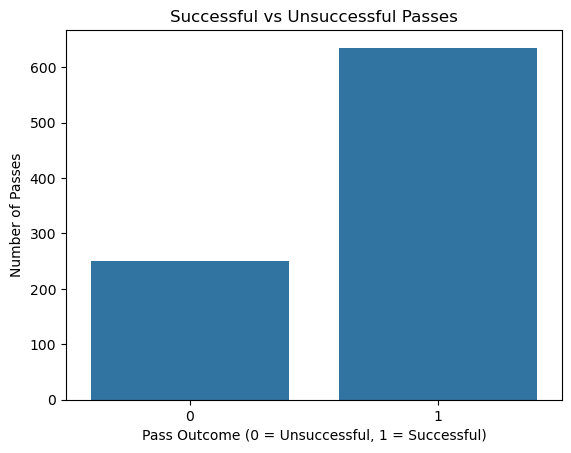

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(
    data=clean_df,
    x="pass_success"
)

plt.title("Successful vs Unsuccessful Passes")
plt.xlabel("Pass Outcome (0 = Unsuccessful, 1 = Successful)")
plt.ylabel("Number of Passes")

plt.show()

In [24]:
clean_df.shape

(886, 17)

In [25]:
# Fill missing pressure values with 0

clean_df["under_pressure"] = (
    clean_df["under_pressure"].fillna(0)
)

# Remove pass type because most values are missing

clean_df = clean_df.drop(
    columns=["pass.type.name"]
)

print(clean_df.isnull().sum())

player.id                0
player.name              0
team.name                0
pass.recipient.id      100
pass.recipient.name    100
location                 0
pass.end_location        0
pass.length              0
pass.angle               0
under_pressure           0
pass.height.name         0
pass_success             0
start_x                  0
start_y                  0
end_x                    0
end_y                    0
dtype: int64


In [26]:
clean_df["under_pressure"] = (
    clean_df["under_pressure"].astype(int)
)

In [27]:
clean_df = pd.get_dummies(
    clean_df,
    columns=["pass.height.name"],
    dtype=int
)

clean_df.head()

,player.id,player.name,team.name,pass.recipient.id,pass.recipient.name,location,pass.end_location,pass.length,pass.angle,under_pressure,pass_success,start_x,start_y,end_x,end_y,pass.height.name_Ground Pass,pass.height.name_High Pass,pass.height.name_Low Pass
4,402661.0,Ibtissam Jraïdi,Morocco Women's,31641.0,Elodie Nakkach,"[61.0, 40.1]","[47.2, 40.5]",13.805796,3.112615,0,1,61.0,40.1,47.2,40.5,1,0,0
6,31641.0,Elodie Nakkach,Morocco Women's,402666.0,Fatima Zahra Tagnaout,"[47.2, 40.1]","[84.6, 2.2]",53.246315,-0.792038,0,1,47.2,40.1,84.6,2.2,0,1,0
9,403283.0,Carolina Arias Vidal,Colombia Women's,388473.0,Jorelyn Andrea Daniela Carabalí Martínez,"[30.4, 80.0]","[15.1, 64.2]",21.993862,-2.340119,0,1,30.4,80.0,15.1,64.2,0,0,1
12,388473.0,Jorelyn Andrea Daniela Carabalí Martínez,Colombia Women's,403277.0,Daniela Alexandra Árias Rojas,"[3.5, 53.1]","[16.6, 29.0]",27.430275,-1.072904,0,1,3.5,53.1,16.6,29.0,1,0,0
15,403277.0,Daniela Alexandra Árias Rojas,Colombia Women's,49945.0,Manuela Vanegas Cataño,"[27.9, 23.9]","[40.7, 2.2]",25.193848,-1.037865,0,1,27.9,23.9,40.7,2.2,1,0,0


In [28]:
feature_columns = [
    "start_x",
    "start_y",
    "end_x",
    "end_y",
    "pass.length",
    "pass.angle",
    "under_pressure",
    "pass.height.name_Ground Pass",
    "pass.height.name_High Pass",
    "pass.height.name_Low Pass"
]

X = clean_df[feature_columns].values

y = clean_df["pass_success"].values

print("Feature shape:", X.shape)
print("Label shape:", y.shape)

Feature shape: (886, 10)
Label shape: (886,)


In [29]:
clean_df.columns.tolist()

['player.id',
 'player.name',
 'team.name',
 'pass.recipient.id',
 'pass.recipient.name',
 'location',
 'pass.end_location',
 'pass.length',
 'pass.angle',
 'under_pressure',
 'pass_success',
 'start_x',
 'start_y',
 'end_x',
 'end_y',
 'pass.height.name_Ground Pass',
 'pass.height.name_High Pass',
 'pass.height.name_Low Pass']

In [30]:

#Normalize numerical features

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X = scaler.fit_transform(X)

print("Normalized feature shape:", X.shape)

Normalized feature shape: (886, 10)


In [31]:
print("Feature shape:", X.shape)
print("Label shape:", y.shape)

print(clean_df["pass_success"].value_counts())

Feature shape: (886, 10)
Label shape: (886,)
pass_success
1    635
0    251
Name: count, dtype: int64


In [32]:
clean_df["possession"] = events_df.loc[
    clean_df.index, "possession"
].values

clean_df["event_index"] = events_df.loc[
    clean_df.index, "index"
].values

clean_df.head()

,player.id,player.name,team.name,pass.recipient.id,pass.recipient.name,location,pass.end_location,pass.length,pass.angle,under_pressure,pass_success,start_x,start_y,end_x,end_y,pass.height.name_Ground Pass,pass.height.name_High Pass,pass.height.name_Low Pass,possession,event_index
4,402661.0,Ibtissam Jraïdi,Morocco Women's,31641.0,Elodie Nakkach,"[61.0, 40.1]","[47.2, 40.5]",13.805796,3.112615,0,1,61.0,40.1,47.2,40.5,1,0,0,2,5
6,31641.0,Elodie Nakkach,Morocco Women's,402666.0,Fatima Zahra Tagnaout,"[47.2, 40.1]","[84.6, 2.2]",53.246315,-0.792038,0,1,47.2,40.1,84.6,2.2,0,1,0,2,7
9,403283.0,Carolina Arias Vidal,Colombia Women's,388473.0,Jorelyn Andrea Daniela Carabalí Martínez,"[30.4, 80.0]","[15.1, 64.2]",21.993862,-2.340119,0,1,30.4,80.0,15.1,64.2,0,0,1,3,10
12,388473.0,Jorelyn Andrea Daniela Carabalí Martínez,Colombia Women's,403277.0,Daniela Alexandra Árias Rojas,"[3.5, 53.1]","[16.6, 29.0]",27.430275,-1.072904,0,1,3.5,53.1,16.6,29.0,1,0,0,3,13
15,403277.0,Daniela Alexandra Árias Rojas,Colombia Women's,49945.0,Manuela Vanegas Cataño,"[27.9, 23.9]","[40.7, 2.2]",25.193848,-1.037865,0,1,27.9,23.9,40.7,2.2,1,0,0,3,16


In [33]:
clean_df = clean_df.reset_index(drop=True)#we prepare a new indexing and drop the old one

clean_df["node_id"] = range(len(clean_df))

print(clean_df[[
    "node_id",
    "player.name",
    "possession",
    "event_index"
]].head(10))

   node_id                               player.name  possession  event_index
0        0                           Ibtissam Jraïdi           2            5
1        1                            Elodie Nakkach           2            7
2        2                      Carolina Arias Vidal           3           10
3        3  Jorelyn Andrea Daniela Carabalí Martínez           3           13
4        4             Daniela Alexandra Árias Rojas           3           16
5        5                    Manuela Vanegas Cataño           3           19
6        6  Jorelyn Andrea Daniela Carabalí Martínez           3           22
7        7                          Nouhaila Benzina           4           23
8        8                            Anissa Lahmari           4           25
9        9                     Fatima Zahra Tagnaout           4           28


In [34]:

import numpy as np

edges = []

groups = clean_df.groupby(
    ["possession", "team.name"]
)

for _, group in groups:

    group = group.sort_values("event_index")

    node_ids = group["node_id"].tolist()

    for i in range(len(node_ids) - 1):

        source = node_ids[i]
        target = node_ids[i + 1]

        # Forward connection only
        edges.append([source, target])

edge_index = np.array(edges).T

print("Number of nodes:", len(clean_df))
print("Number of directed edges:", edge_index.shape[1])
print("Edge index shape:", edge_index.shape)


Number of nodes: 886
Number of directed edges: 638
Edge index shape: (2, 638)


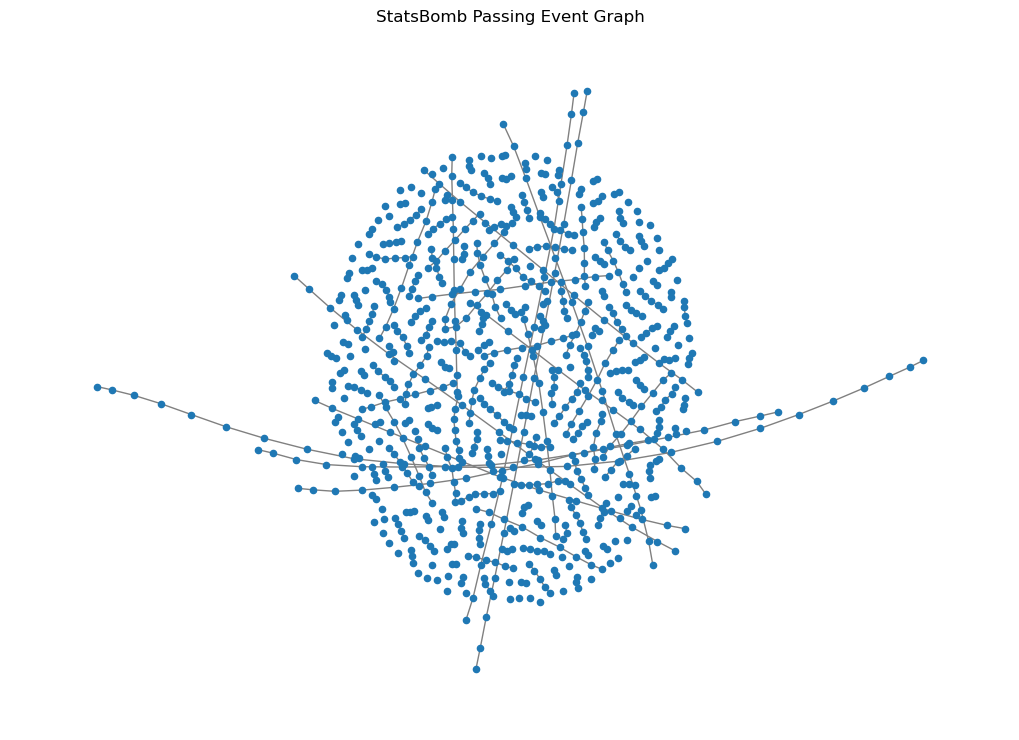

In [35]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.Graph()

G.add_nodes_from(range(len(clean_df)))

G.add_edges_from(edge_index.T.tolist())

plt.figure(figsize=(10, 7))

nx.draw(
    G,
    node_size=20,
    with_labels=False,
    edge_color="gray"
)

plt.title("StatsBomb Passing Event Graph")

plt.show()

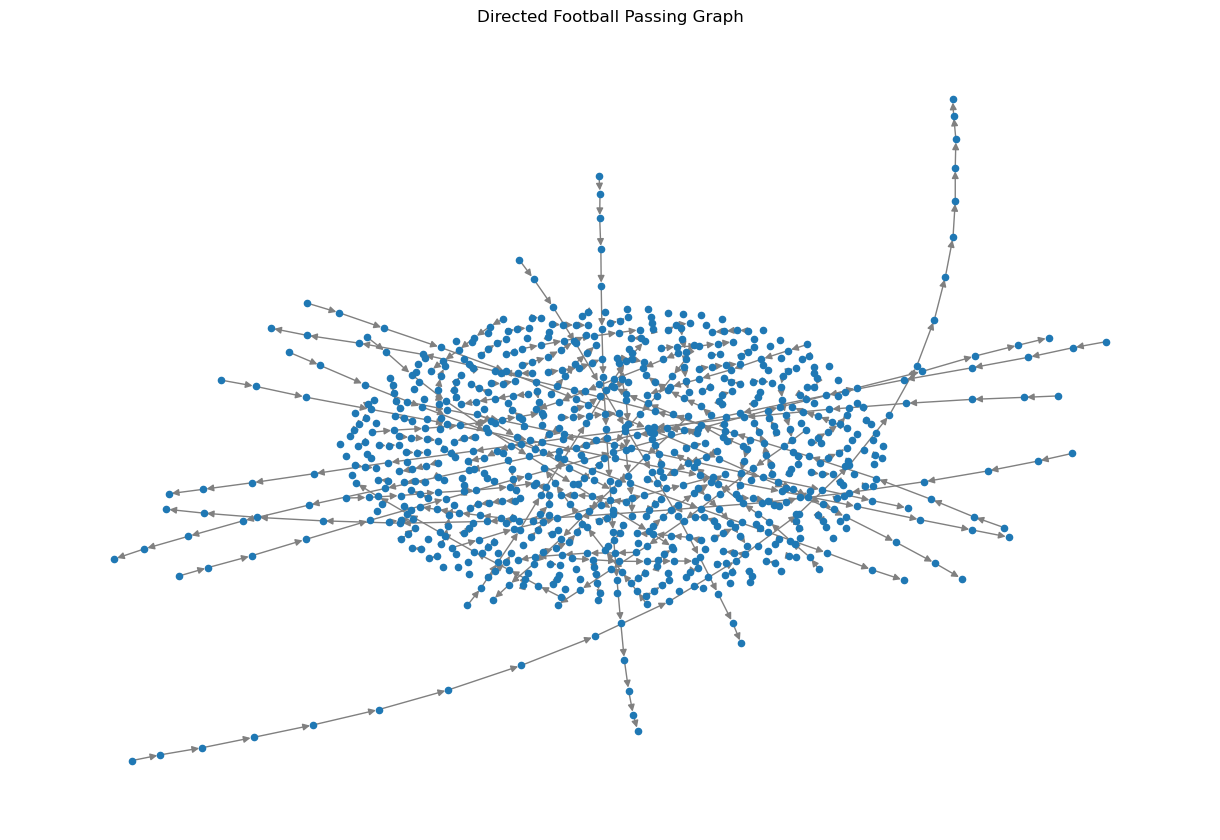

In [36]:
G = nx.DiGraph()

G.add_nodes_from(range(len(clean_df)))

G.add_edges_from(edges)

plt.figure(figsize=(12, 8))

nx.draw(
    G,
    node_size=20,
    with_labels=False,
    edge_color="gray",
    arrows=True,
    arrowsize=10
)

plt.title("Directed Football Passing Graph")
plt.show()

In [37]:
import torch
import torch.nn.functional as F

from torch.nn import Linear
from torch_geometric.nn import MessagePassing

In [38]:
#Create directed graph convolution layer
class DirectedGCNConv(MessagePassing):

    def __init__(self, in_channels, out_channels):

        super().__init__(
            aggr="mean",
            flow="source_to_target"
        )
#information flow from current to next
        self.lin_self = Linear(
            in_channels, out_channels
        )
#information from previous
        self.lin_neighbour = Linear(
            in_channels, out_channels
        )

    def forward(self, x, edge_index):

        # Aggregate information from incoming neighbours

        neighbour_features = self.propagate(
            edge_index, x=x
        )

        # Combine self information and neighbour information

        out = (
            self.lin_self(x) +
            self.lin_neighbour(neighbour_features)
        )

        return out

In [39]:
#Two-layer Directed GCN
class DirectedGCN(torch.nn.Module):

    def __init__(self, input_features, hidden_channels, num_classes):

        super().__init__()

        # First graph convolution layer
        self.conv1 = DirectedGCNConv(
            input_features, hidden_channels
        )

        # Second graph convolution layer
        self.conv2 = DirectedGCNConv(
            hidden_channels, 16
        )

        # Output classification layer
        self.fc = Linear(16, num_classes)

    def forward(self, x, edge_index):

        # First layer
        x = self.conv1(x, edge_index)
        x = F.relu(x)

        # Second layer
        x = self.conv2(x, edge_index)
        x = F.relu(x)

        # Classification
        x = self.fc(x)

        return x

In [40]:
model = DirectedGCN(
    input_features=10,
    hidden_channels=32,
    num_classes=2
)

print(model)

DirectedGCN(
  (conv1): DirectedGCNConv()
  (conv2): DirectedGCNConv()
  (fc): Linear(in_features=16, out_features=2, bias=True)
)


In [41]:
all_passes = []

for i, match_id in enumerate(matches_df["match_id"], start=1):

    url = f"{BASE_URL}/events/{match_id}.json"

    try:
        response = requests.get(url, timeout=20)
        response.raise_for_status()

        match_events = response.json()
        match_df = pd.json_normalize(match_events)

        match_passes = match_df[
            match_df["type.name"] == "Pass"
        ].copy()

        match_passes["match_id"] = match_id

        all_passes.append(match_passes)

        print(f"Downloaded match {i}/64")

    except requests.exceptions.RequestException as e:
        print(f"Match {i} failed: {e}")

all_passes_df = pd.concat(all_passes, ignore_index=True)

print("Total pass events:", len(all_passes_df))

Downloaded match 1/64
Downloaded match 2/64
Downloaded match 3/64
Downloaded match 4/64
Downloaded match 5/64
Downloaded match 6/64
Downloaded match 7/64
Downloaded match 8/64
Downloaded match 9/64
Downloaded match 10/64
Downloaded match 11/64
Downloaded match 12/64
Downloaded match 13/64
Downloaded match 14/64
Downloaded match 15/64
Downloaded match 16/64
Downloaded match 17/64
Downloaded match 18/64
Downloaded match 19/64
Downloaded match 20/64
Downloaded match 21/64
Downloaded match 22/64
Downloaded match 23/64
Downloaded match 24/64
Downloaded match 25/64
Downloaded match 26/64
Downloaded match 27/64
Downloaded match 28/64
Downloaded match 29/64
Downloaded match 30/64
Downloaded match 31/64
Downloaded match 32/64
Downloaded match 33/64
Downloaded match 34/64
Downloaded match 35/64
Downloaded match 36/64
Downloaded match 37/64
Downloaded match 38/64
Downloaded match 39/64
Downloaded match 40/64
Downloaded match 41/64
Downloaded match 42/64
Downloaded match 43/64
Downloaded match 44/

In [42]:
print("Total matches:", all_passes_df["match_id"].nunique())
print("Total pass events:", len(all_passes_df))
print("Missing match IDs:", all_passes_df["match_id"].isna().sum())

Total matches: 64
Total pass events: 59780
Missing match IDs: 0


In [43]:
all_passes_df = all_passes_df[
    all_passes_df["pass.outcome.name"] != "Unknown"
].copy()

all_passes_df["pass_success"] = (
    all_passes_df["pass.outcome.name"].isna()
).astype(int)

print(all_passes_df["pass_success"].value_counts())

pass_success
1    44257
0    15212
Name: count, dtype: int64


In [44]:
from sklearn.model_selection import train_test_split

match_ids = all_passes_df["match_id"].unique()

train_ids, remaining_ids = train_test_split(
    match_ids, test_size=0.30, random_state=42
)

val_ids, test_ids = train_test_split(
    remaining_ids, test_size=0.50, random_state=42
)

print("Training matches:", len(train_ids))
print("Validation matches:", len(val_ids))
print("Testing matches:", len(test_ids))

Training matches: 44
Validation matches: 10
Testing matches: 10


In [45]:
train_df = all_passes_df[
    all_passes_df["match_id"].isin(train_ids)
].copy()

val_df = all_passes_df[
    all_passes_df["match_id"].isin(val_ids)
].copy()

test_df = all_passes_df[
    all_passes_df["match_id"].isin(test_ids)
].copy()

print("Training passes:", len(train_df))
print("Validation passes:", len(val_df))
print("Testing passes:", len(test_df))

Training passes: 41050
Validation passes: 9011
Testing passes: 9408


In [46]:
print("Training labels:")
print(train_df["pass_success"].value_counts())

print("\nValidation labels:")
print(val_df["pass_success"].value_counts())

print("\nTesting labels:")
print(test_df["pass_success"].value_counts())

Training labels:
pass_success
1    30466
0    10584
Name: count, dtype: int64

Validation labels:
pass_success
1    6712
0    2299
Name: count, dtype: int64

Testing labels:
pass_success
1    7079
0    2329
Name: count, dtype: int64


In [47]:
print(all_passes_df.columns.tolist())

['id', 'index', 'period', 'timestamp', 'minute', 'second', 'possession', 'duration', 'type.id', 'type.name', 'possession_team.id', 'possession_team.name', 'play_pattern.id', 'play_pattern.name', 'team.id', 'team.name', 'tactics.formation', 'tactics.lineup', 'related_events', 'location', 'player.id', 'player.name', 'position.id', 'position.name', 'pass.recipient.id', 'pass.recipient.name', 'pass.length', 'pass.angle', 'pass.height.id', 'pass.height.name', 'pass.end_location', 'pass.body_part.id', 'pass.body_part.name', 'pass.type.id', 'pass.type.name', 'out', 'carry.end_location', 'pass.outcome.id', 'pass.outcome.name', 'pass.assisted_shot_id', 'pass.shot_assist', 'shot.one_on_one', 'shot.statsbomb_xg', 'shot.end_location', 'shot.key_pass_id', 'shot.body_part.id', 'shot.body_part.name', 'shot.type.id', 'shot.type.name', 'shot.outcome.id', 'shot.outcome.name', 'shot.technique.id', 'shot.technique.name', 'shot.freeze_frame', 'goalkeeper.technique.id', 'goalkeeper.technique.name', 'goalkee

In [48]:
# Extract starting X and Y coordinates
all_passes_df["start_x"] = all_passes_df["location"].apply(lambda x: x[0])
all_passes_df["start_y"] = all_passes_df["location"].apply(lambda x: x[1])

# Extract ending X and Y coordinates
all_passes_df["end_x"] = all_passes_df["pass.end_location"].apply(lambda x: x[0])
all_passes_df["end_y"] = all_passes_df["pass.end_location"].apply(lambda x: x[1])

# Display the extracted coordinates
print(all_passes_df[["start_x", "start_y", "end_x", "end_y"]].head())

   start_x  start_y  end_x  end_y
0     61.0     40.1   47.2   40.5
1     47.2     40.1   84.6    2.2
2     30.4     80.0   15.1   64.2
3      3.5     53.1   16.6   29.0
4     27.9     23.9   40.7    2.2


In [49]:
print(all_passes_df[
    ["start_x", "start_y", "end_x", "end_y",
     "pass.length", "pass.angle", "under_pressure",
     "pass.height.name"]
].isnull().sum())

start_x                 0
start_y                 0
end_x                   0
end_y                   0
pass.length             0
pass.angle              0
under_pressure      48852
pass.height.name        0
dtype: int64


In [50]:
all_passes_df["under_pressure"] = (
    all_passes_df["under_pressure"].fillna(0).astype(int)
)

print(all_passes_df["under_pressure"].value_counts())

under_pressure
0    48852
1    10617
Name: count, dtype: int64


In [51]:
all_passes_df = pd.get_dummies(
    all_passes_df,
    columns=["pass.height.name"],
    dtype=int
)

print(all_passes_df.filter(like="pass.height.name_").head())

   pass.height.name_Ground Pass  pass.height.name_High Pass  \
0                             1                           0   
1                             0                           1   
2                             0                           0   
3                             1                           0   
4                             1                           0   

   pass.height.name_Low Pass  
0                          0  
1                          0  
2                          1  
3                          0  
4                          0  


In [52]:
feature_columns = [
    "start_x",
    "start_y",
    "end_x",
    "end_y",
    "pass.length",
    "pass.angle",
    "under_pressure",
    "pass.height.name_Ground Pass",
    "pass.height.name_High Pass",
    "pass.height.name_Low Pass"
]

X = all_passes_df[feature_columns].values
y = all_passes_df["pass_success"].values

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

Feature matrix shape: (59469, 10)
Target vector shape: (59469,)


In [53]:
from sklearn.preprocessing import StandardScaler

# Separate features using match IDs
X_train = all_passes_df.loc[
    all_passes_df["match_id"].isin(train_ids), feature_columns
].values

X_val = all_passes_df.loc[
    all_passes_df["match_id"].isin(val_ids), feature_columns
].values

X_test = all_passes_df.loc[
    all_passes_df["match_id"].isin(test_ids), feature_columns
].values

# Separate labels
y_train = train_df["pass_success"].values
y_val = val_df["pass_success"].values
y_test = test_df["pass_success"].values

# Scale features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (41050, 10) (41050,)
Validation: (9011, 10) (9011,)
Testing: (9408, 10) (9408,)


In [54]:
import torch
from torch_geometric.data import Data

In [55]:
def create_graph(df, X, y):

    df = df.reset_index(drop=True)

    edges = []

    # Group passes by match, possession and team
    groups = df.groupby(
        ["match_id", "possession", "team.id"]
    )

    for _, group in groups:

        group = group.sort_values("index")
        node_ids = group.index.tolist()

        # Connect each pass to the next pass
        for i in range(len(node_ids) - 1):

            source = node_ids[i]
            target = node_ids[i + 1]

            edges.append([source, target])

    # Convert edges into PyTorch format
    if len(edges) > 0:
        edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
    else:
        edge_index = torch.empty((2, 0), dtype=torch.long)

    # Convert features and labels into tensors
    x = torch.tensor(X, dtype=torch.float)
    y = torch.tensor(y, dtype=torch.long)

    return Data(x=x, edge_index=edge_index, y=y)
    

In [56]:
train_graph = create_graph(train_df, X_train, y_train)

val_graph = create_graph(val_df, X_val, y_val)

test_graph = create_graph(test_df, X_test, y_test)

print("Training graph:", train_graph)
print("Validation graph:", val_graph)
print("Testing graph:", test_graph)

Training graph: Data(x=[41050, 10], edge_index=[2, 30659], y=[41050])
Validation graph: Data(x=[9011, 10], edge_index=[2, 6745], y=[9011])
Testing graph: Data(x=[9408, 10], edge_index=[2, 7133], y=[9408])


In [58]:
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import MessagePassing


class DirectedGCNConv(MessagePassing):

    def __init__(self, in_channels, out_channels):
        super().__init__(aggr="mean", flow="source_to_target")

        self.lin_self = nn.Linear(in_channels, out_channels)
        self.lin_neighbour = nn.Linear(in_channels, out_channels)

    def forward(self, x, edge_index):

        neighbour_features = self.propagate(edge_index, x=x)

        out = self.lin_self(x) + self.lin_neighbour(neighbour_features)

        return out


class DirectedGCN(nn.Module):

    def __init__(self, input_features, hidden_channels, num_classes):
        super().__init__()

        self.conv1 = DirectedGCNConv(input_features, hidden_channels)
        self.conv2 = DirectedGCNConv(hidden_channels, 16)
        self.fc = nn.Linear(16, num_classes)

    def forward(self, x, edge_index):

        x = self.conv1(x, edge_index)
        x = F.relu(x)

        x = self.conv2(x, edge_index)
        x = F.relu(x)

        x = self.fc(x)

        return x

In [59]:
model = DirectedGCN(
    input_features=10,
    hidden_channels=32,
    num_classes=2
)

print(model)

DirectedGCN(
  (conv1): DirectedGCNConv()
  (conv2): DirectedGCNConv()
  (fc): Linear(in_features=16, out_features=2, bias=True)
)


In [60]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Model ready for training!")

Model ready for training!


In [69]:
def train():

    model.train()

    optimizer.zero_grad()

    output = model(
        train_graph.x,
        train_graph.edge_index
    )

    loss = criterion(output, train_graph.y)

    loss.backward()

    optimizer.step()

    return loss.item()

In [70]:
def validate():

    model.eval()

    with torch.no_grad():

        output = model(
            val_graph.x,
            val_graph.edge_index
        )

        loss = criterion(output, val_graph.y)

        predictions = output.argmax(dim=1)

        accuracy = (
            predictions == val_graph.y
        ).float().mean()

    return loss.item(), accuracy.item()
    

In [63]:
epochs = 30

for epoch in range(epochs):

    train_loss = train()

    val_loss, val_accuracy = validate()

    print(
        f"Epoch {epoch+1:02d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

Epoch 01/30 | Train Loss: 0.6115 | Val Loss: 0.6063 | Val Accuracy: 0.7449
Epoch 02/30 | Train Loss: 0.6081 | Val Loss: 0.6029 | Val Accuracy: 0.7449
Epoch 03/30 | Train Loss: 0.6048 | Val Loss: 0.5996 | Val Accuracy: 0.7449
Epoch 04/30 | Train Loss: 0.6016 | Val Loss: 0.5964 | Val Accuracy: 0.7449
Epoch 05/30 | Train Loss: 0.5985 | Val Loss: 0.5932 | Val Accuracy: 0.7449
Epoch 06/30 | Train Loss: 0.5954 | Val Loss: 0.5901 | Val Accuracy: 0.7449
Epoch 07/30 | Train Loss: 0.5924 | Val Loss: 0.5870 | Val Accuracy: 0.7449
Epoch 08/30 | Train Loss: 0.5895 | Val Loss: 0.5840 | Val Accuracy: 0.7449
Epoch 09/30 | Train Loss: 0.5866 | Val Loss: 0.5810 | Val Accuracy: 0.7449
Epoch 10/30 | Train Loss: 0.5837 | Val Loss: 0.5781 | Val Accuracy: 0.7449
Epoch 11/30 | Train Loss: 0.5809 | Val Loss: 0.5751 | Val Accuracy: 0.7449
Epoch 12/30 | Train Loss: 0.5781 | Val Loss: 0.5722 | Val Accuracy: 0.7449
Epoch 13/30 | Train Loss: 0.5753 | Val Loss: 0.5693 | Val Accuracy: 0.7449
Epoch 14/30 | Train Loss:

In [64]:
model.eval()

with torch.no_grad():
    val_output = model(
        val_graph.x,
        val_graph.edge_index
    )

    val_predictions = val_output.argmax(dim=1)

print("Actual labels:")
print(torch.bincount(val_graph.y))

print("\nPredicted labels:")
print(torch.bincount(val_predictions))

Actual labels:
tensor([2299, 6712])

Predicted labels:
tensor([   3, 9008])


In [65]:
#we can see class imbalance here so give more importance to the unsuccessful passess


In [66]:
#class weight calculation

class_counts = torch.bincount(train_graph.y)

class_weights = len(train_graph.y) / (
    2 * class_counts.float()
)

class_weights = class_weights.to(train_graph.x.device)

print("Class counts:", class_counts)
print("Class weights:", class_weights)

Class counts: tensor([10584, 30466])
Class weights: tensor([1.9392, 0.6737])


In [67]:

#reinitialize the model again after changing the weight

model = DirectedGCN(
    input_features=10,
    hidden_channels=32,
    num_classes=2
)

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Model reset with class-weighted loss!")

Model reset with class-weighted loss!


In [71]:

#train again
epochs = 30

for epoch in range(epochs):

    train_loss = train()

    val_loss, val_accuracy = validate()

    print(
        f"Epoch {epoch+1:02d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

Epoch 01/30 | Train Loss: 0.6048 | Val Loss: 0.6040 | Val Accuracy: 0.7378
Epoch 02/30 | Train Loss: 0.6010 | Val Loss: 0.6002 | Val Accuracy: 0.7383
Epoch 03/30 | Train Loss: 0.5972 | Val Loss: 0.5964 | Val Accuracy: 0.7392
Epoch 04/30 | Train Loss: 0.5935 | Val Loss: 0.5927 | Val Accuracy: 0.7383
Epoch 05/30 | Train Loss: 0.5897 | Val Loss: 0.5889 | Val Accuracy: 0.7380
Epoch 06/30 | Train Loss: 0.5860 | Val Loss: 0.5853 | Val Accuracy: 0.7365
Epoch 07/30 | Train Loss: 0.5824 | Val Loss: 0.5817 | Val Accuracy: 0.7374
Epoch 08/30 | Train Loss: 0.5789 | Val Loss: 0.5782 | Val Accuracy: 0.7367
Epoch 09/30 | Train Loss: 0.5754 | Val Loss: 0.5747 | Val Accuracy: 0.7357
Epoch 10/30 | Train Loss: 0.5720 | Val Loss: 0.5714 | Val Accuracy: 0.7362
Epoch 11/30 | Train Loss: 0.5688 | Val Loss: 0.5682 | Val Accuracy: 0.7367
Epoch 12/30 | Train Loss: 0.5656 | Val Loss: 0.5651 | Val Accuracy: 0.7370
Epoch 13/30 | Train Loss: 0.5626 | Val Loss: 0.5622 | Val Accuracy: 0.7379
Epoch 14/30 | Train Loss:

In [72]:

#We need to see whether the number of predicted unsuccessful passes has increased from just 3.

model.eval()

with torch.no_grad():
    val_output = model(
        val_graph.x,
        val_graph.edge_index
    )

    val_predictions = val_output.argmax(dim=1)

print("Actual labels:")
print(torch.bincount(val_graph.y))

print("\nPredicted labels:")
print(torch.bincount(val_predictions))

Actual labels:
tensor([2299, 6712])

Predicted labels:
tensor([3316, 5695])


In [73]:
from sklearn.metrics import classification_report, confusion_matrix

print("Confusion Matrix:")
print(confusion_matrix(val_graph.y.numpy(), val_predictions.numpy()))

print("\nClassification Report:")
print(classification_report(
    val_graph.y.numpy(),
    val_predictions.numpy(),
    target_names=["Unsuccessful", "Successful"]
))

Confusion Matrix:
[[1698  601]
 [1618 5094]]

Classification Report:
              precision    recall  f1-score   support

Unsuccessful       0.51      0.74      0.60      2299
  Successful       0.89      0.76      0.82      6712

    accuracy                           0.75      9011
   macro avg       0.70      0.75      0.71      9011
weighted avg       0.80      0.75      0.77      9011



In [74]:
#befre testing try to improve the accuracy
epochs = 30

for epoch in range(epochs):

    train_loss = train()

    val_loss, val_accuracy = validate()

    print(
        f"Epoch {epoch+31:02d}/60 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )




Epoch 31/60 | Train Loss: 0.5289 | Val Loss: 0.5300 | Val Accuracy: 0.7555
Epoch 32/60 | Train Loss: 0.5278 | Val Loss: 0.5290 | Val Accuracy: 0.7564
Epoch 33/60 | Train Loss: 0.5268 | Val Loss: 0.5281 | Val Accuracy: 0.7582
Epoch 34/60 | Train Loss: 0.5258 | Val Loss: 0.5272 | Val Accuracy: 0.7592
Epoch 35/60 | Train Loss: 0.5248 | Val Loss: 0.5263 | Val Accuracy: 0.7601
Epoch 36/60 | Train Loss: 0.5238 | Val Loss: 0.5255 | Val Accuracy: 0.7604
Epoch 37/60 | Train Loss: 0.5229 | Val Loss: 0.5247 | Val Accuracy: 0.7604
Epoch 38/60 | Train Loss: 0.5220 | Val Loss: 0.5239 | Val Accuracy: 0.7610
Epoch 39/60 | Train Loss: 0.5211 | Val Loss: 0.5231 | Val Accuracy: 0.7605
Epoch 40/60 | Train Loss: 0.5202 | Val Loss: 0.5224 | Val Accuracy: 0.7615
Epoch 41/60 | Train Loss: 0.5193 | Val Loss: 0.5217 | Val Accuracy: 0.7622
Epoch 42/60 | Train Loss: 0.5185 | Val Loss: 0.5210 | Val Accuracy: 0.7633
Epoch 43/60 | Train Loss: 0.5176 | Val Loss: 0.5203 | Val Accuracy: 0.7633
Epoch 44/60 | Train Loss:

In [75]:

#Lets check whether the unsuccessful pass performance has improved too.
model.eval()

with torch.no_grad():
    val_output = model(
        val_graph.x,
        val_graph.edge_index
    )

    val_predictions = val_output.argmax(dim=1)

print(classification_report(
    val_graph.y.numpy(),
    val_predictions.numpy(),
    target_names=["Unsuccessful", "Successful"]
))

              precision    recall  f1-score   support

Unsuccessful       0.53      0.74      0.62      2299
  Successful       0.90      0.77      0.83      6712

    accuracy                           0.77      9011
   macro avg       0.71      0.76      0.72      9011
weighted avg       0.80      0.77      0.78      9011



In [76]:

#TESTING

from sklearn.metrics import classification_report, confusion_matrix

model.eval()

with torch.no_grad():
    test_output = model(test_graph.x, test_graph.edge_index)
    test_predictions = test_output.argmax(dim=1)

print("Confusion Matrix:")
print(confusion_matrix(
    test_graph.y.numpy(),
    test_predictions.numpy()
))

print("\nClassification Report:")
print(classification_report(
    test_graph.y.numpy(),
    test_predictions.numpy(),
    target_names=["Unsuccessful", "Successful"]
))

Confusion Matrix:
[[1740  589]
 [1514 5565]]

Classification Report:
              precision    recall  f1-score   support

Unsuccessful       0.53      0.75      0.62      2329
  Successful       0.90      0.79      0.84      7079

    accuracy                           0.78      9408
   macro avg       0.72      0.77      0.73      9408
weighted avg       0.81      0.78      0.79      9408

